# Joint response-time and Thurstonian item response theory model

Fit choices and response times together. The TIRT choice model estimates
how uncertain each choice is. The timing model estimates how that
uncertainty relates to time on the same response.
[Guo et al. (2024)](https://doi.org/10.1177/00131644231171193)

## Model choices and times

Let $p$ index people and $b$ the two-statement block. Write $j,k$ for
the first and second statements, and $\theta_{p,t(j)}$ for the score on
the trait measured by $j$. The response $Y_{pb}=1$ favors $j$. Define

$$
D_{pb}=\lambda_j\theta_{p,t(j)}-\lambda_k\theta_{p,t(k)}-\gamma_b,
\qquad q_{pb}=P(Y_{pb}=1)=\Phi(D_{pb}).
$$

The signed loading $\lambda_j$ is the product of a positive loading
magnitude and the design keying sign.
The comparison threshold $\gamma_b$ shifts the difference between the
utilities. Each statement has residual variance 0.5, so the residual SD
of the difference is one. $\Phi$ is the standard normal cumulative
distribution function.

Use both answer probabilities to calculate the entropy of the choice:

$$
H_{pb}=-q_{pb}\log q_{pb}-(1-q_{pb})\log(1-q_{pb}).
$$

Entropy is greatest when both answers have probability $1/2$. It falls
as one of the answers becomes more likely. The observed time $RT_{pb}$,
in seconds, follows

$$
\log RT_{pb}\sim\mathcal N(\mu_{pb},\sigma_b^2),\qquad
\mu_{pb}=\kappa_b-v_p+\rho_b H_{pb}.
$$

Time intensity $\kappa_b$ is the block's reference log time. Larger
person speed $v_p$ shortens the predicted time. A positive slope $\rho_b$
means less certain choices take longer on average on the log-time scale.
The residual SD $\sigma_b$ captures variation in log time around this mean.
The joint likelihood uses the choice and timing terms for each observed dyad.

### Set the reference scales

Traits have mean zero and SD one. Design keying fixes loading signs.
The speed prior is $v_p\sim\mathcal N(0,1)$, and the timing model estimates
one $\sigma_b$ per block.
[Guo et al. (2024), Parameter Estimation](https://pmc.ncbi.nlm.nih.gov/articles/PMC11095319/)

## Read the design and paired observations

Use 100 synthetic respondents and nine two-statement blocks. The design
gives each statement's trait and keying direction.

In [1]:
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example("jrt_tirt", model="TIRT", n_persons=100)
design = example.data.design
design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,S1,theta1,1
1,B1,2,S2,theta2,1
2,B2,1,S3,theta2,1


Match choices to times by person_id and block_id. Each row contains one
choice and a time in seconds. A 1 favors the first statement and a 0 favors
the second.

In [2]:
responses = example.data.responses.frame.merge(
    example.response_times,
    on=["person_id", "block_id"],
    validate="one_to_one",
)
responses.head(3).round({"seconds": 2})

,person_id,block_id,statement_1,statement_2,response,seconds
0,J001,B1,S1,S2,0,37.58
1,J001,B2,S3,S4,0,108.73
2,J001,B3,S5,S6,0,24.88


## Build the PyMC model

The indexing code aligns each response row with person, block, statement
and trait coordinates.

In [3]:
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from pymc.model.fgraph import clone_model

from pyfcirt.models.dist import TIRTDistribution

people = pd.Index(responses.person_id.unique(), name="person")
blocks = pd.Index(design.block_id.unique(), name="block")
statements = design.drop_duplicates("statement_id").set_index("statement_id")
traits = pd.Index(statements.trait.unique(), name="trait")
person = people.get_indexer(responses.person_id)
block = blocks.get_indexer(responses.block_id)
pair = np.column_stack(
    [
        statements.index.get_indexer(responses.statement_1),
        statements.index.get_indexer(responses.statement_2),
    ]
)
trait = traits.get_indexer(statements.trait)[pair]
keying = statements.keying.to_numpy(dtype=float)
y = responses.response.to_numpy(dtype=int)
corr_row, corr_col = np.triu_indices(len(traits), k=1)
coords = {
    "person": people,
    "trait": traits,
    "statement": statements.index,
    "block": blocks,
    "obs": responses.index,
    "trait_pair": [f"{traits[a]} / {traits[b]}" for a, b in zip(corr_row, corr_col, strict=True)],
}

Define the TIRT choice model once. Create a copy for JRT–TIRT, then add
the timing likelihood using the choice probabilities from that copy.

In [4]:
effects = np.zeros((len(responses), 2))
variances = np.full((len(responses), 2), 0.5)

with pm.Model(coords=coords) as tirt:
    # LKJ correlation has unit diagonal: trait population SDs are fixed at 1.
    chol = pm.LKJCorr("trait_cholesky", n=len(traits), eta=1)
    pm.Deterministic(
        "trait_correlation",
        (chol @ chol.T)[corr_row, corr_col],
        dims="trait_pair",
    )
    theta = pm.MvNormal(
        "theta",
        mu=np.zeros(len(traits)),
        chol=chol,
        shape=(len(people), len(traits)),
        dims=("person", "trait"),
    )
    loading_magnitude = pm.LogNormal("loading_magnitude", 0, 0.5, dims="statement")
    loading = keying * loading_magnitude  # q_j a_j supplies the sign of each slope.
    gamma = pm.Normal("gamma", 0, 2, dims="block")
    TIRTDistribution(
        "response",
        theta[person[:, None], trait],
        loading[pair],
        gamma[block, None],
        statement_effect=effects,
        residual_variance=variances,
        observed=y,
        dims="obs",
    )

In [5]:
model = clone_model(tirt)
with model:
    choice = model["response"]
    # Choice entropy H = -sum(p_k * log(p_k)).
    log_choice = pt.stack([pm.logp(choice, 0), pm.logp(choice, 1)], axis=-1)
    entropy = -(pt.exp(log_choice) * log_choice).sum(axis=-1)
    speed = pm.Normal("speed", 0, 1, dims="person")
    time_intensity = pm.Normal("time_intensity", 0, 1, dims="block")
    entropy_slope = pm.Normal("entropy_slope", 0, 1, dims="block")
    sigma_time = pm.InverseGamma("sigma_time", alpha=1, beta=1, dims="block")
    # E[log(time)] = intensity - speed + entropy_slope * H.
    pm.LogNormal(
        "rt",
        mu=time_intensity[block] - speed[person] + entropy_slope[block] * entropy,
        sigma=sigma_time[block],
        observed=responses.seconds.to_numpy(),
        dims="obs",
    )

## Check the time prior

This prior density shows the residual SD of log time for B1. Larger draws
allow a wider spread of times for respondents with the same predictors.
This inverse-gamma prior has a long right tail. The displayed mean
summarizes the 64 simulated values.
The underlying prior has no finite mean.

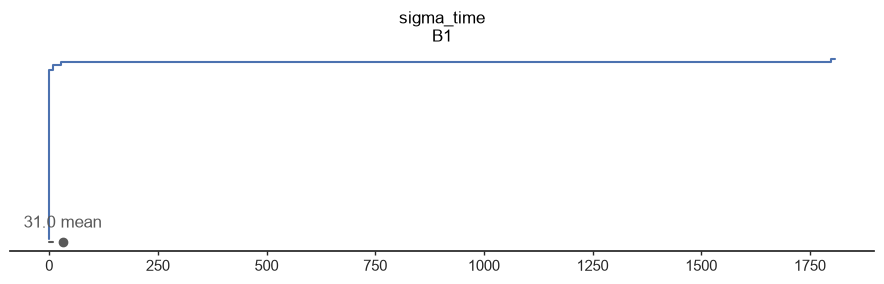

In [6]:
with model:
    prior = pm.sample_prior_predictive(
        draws=64,
        random_seed=2026111704,
        backend="jax",
        var_names=["sigma_time"],
    )
az.plot_dist(
    prior,
    group="prior",
    var_names=["sigma_time"],
    coords={"block": [blocks[0]]},
)
plt.gcf().set_size_inches(9, 3)
plt.tight_layout()
plt.show()

## Fit and diagnose

The results shown use four CPU BlackJAX chains with 1,500 warmup iterations
and 3,000 retained draws per chain. The vectorized chain setting runs the
chains on one device.

In [7]:
with model:
    idata = pm.sample(draws=3000, tune=1500, chains=4, random_seed=2026111704)

The maximum R-hat is 1.011, slightly above the 1.01 screening value.
The smallest bulk and tail effective sample sizes are 458 and 827.
There are zero divergences.

In [8]:
import arviz as az
import numpy as np

posterior = idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(idata.sample_stats.diverging.sum()))

Max R-hat: 1.011
Min bulk / tail ESS: 458 / 827
Divergences: 0


The density and rank panels inspect timing parameters in B1. The time
intensity shows differences among chains. Its chain means range from
1.290 to 1.336 log seconds, with Monte Carlo standard errors of 0.009 to
0.018 for those means.

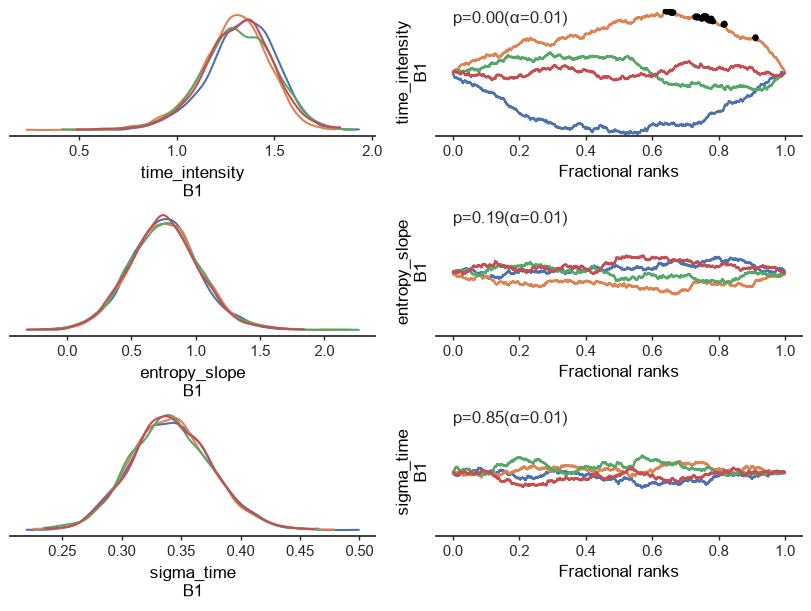

In [9]:
rank_posterior = idata.posterior.to_dataset()[
    ["time_intensity", "entropy_slope", "sigma_time"]
].sel(block=blocks[:1])
azp.plot_rank_dist(
    rank_posterior,
    compact=False,
    backend="matplotlib",
    figure_kwargs={"figsize": (8, 6), "layout": "constrained"},
)
plt.show()

## Interpret the timing estimates

The B1 time intensity is on the log-seconds scale. Exponentiating
time intensity gives a reference median of about 3.7 seconds at zero
speed and zero choice entropy. The reference-median point estimate still
rounds to 3.7 seconds when any one chain is left out.

In [10]:
timing = az.summary(
    idata,
    var_names=["time_intensity", "entropy_slope", "sigma_time"],
    coords={"block": ["B1"]},
    kind="stats",
    ci_kind="hdi",
    ci_prob=0.95,
    round_to=2,
)
timing

,mean,sd,hdi95_lb,hdi95_ub
time_intensity[B1],1.31,0.18,0.95,1.65
entropy_slope[B1],0.76,0.28,0.21,1.31
sigma_time[B1],0.34,0.03,0.28,0.41


## Check choices and response times

First compare the overall proportion of choices favoring the first
statement. The marker shows the observed proportion and the curve shows
the proportions from replicated answers.

D:\CodexEnvs\pyfcirt\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

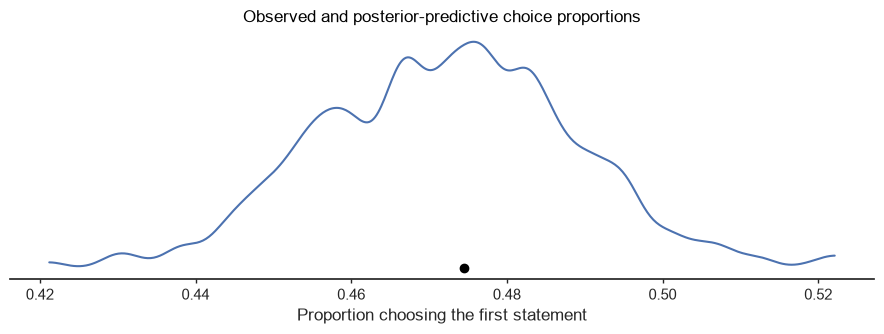

In [11]:
with model:
    predictive = pm.sample_posterior_predictive(
        idata.sel(draw=slice(None, None, 20)),
        var_names=["response", "rt"],
        random_seed=2026111705,
        backend="jax",
    )

az.plot_ppc_tstat(predictive, var_names=["response"], t_stat="mean")
plt.gcf().set_size_inches(9, 3.5)
plt.xlabel("Proportion choosing the first statement")
plt.title("Observed and posterior-predictive choice proportions")
plt.tight_layout()
plt.show()

Next compare observed and replicated log response times. The shared scale
makes differences in the spread or tails easier to see.

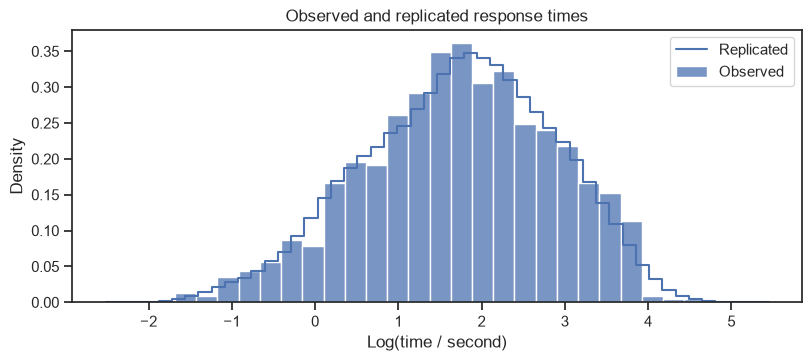

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
sns.histplot(
    x=np.log(responses.seconds),
    bins=25,
    stat="density",
    label="Observed",
    ax=ax,
)
replicated = np.log(predictive.posterior_predictive.rt).values.ravel()
sns.histplot(
    x=replicated,
    bins=50,
    stat="density",
    element="step",
    fill=False,
    label="Replicated",
    ax=ax,
)
ax.set(
    xlabel="Log(time / second)",
    title="Observed and replicated response times",
)
ax.legend()
plt.show()

## Compare trait scores with TIRT

Fit TIRT to the same choices so that both models have the same trait
scale, choice likelihood and priors. Each dot compares one respondent's
posterior mean trait score. The diagonal marks equal scores.

In [13]:
with tirt:
    tirt_fit = pm.sample(draws=1200, tune=1800, chains=4)

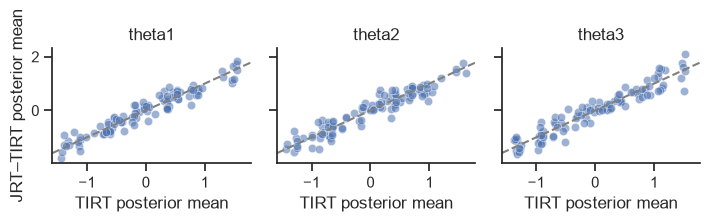

In [14]:
import xarray as xr

traits = idata.posterior.theta.trait.values
choice_means = tirt_fit.posterior.theta.sel(trait=traits).mean(("chain", "draw"))
extended_means = idata.posterior.theta.mean(("chain", "draw"))
scores = xr.Dataset({"TIRT": choice_means, "JRT–TIRT": extended_means}).to_dataframe().reset_index()
chart = sns.relplot(
    data=scores,
    x="TIRT",
    y="JRT–TIRT",
    col="trait",
    col_wrap=3,
    height=2.2,
    aspect=1.1,
    alpha=0.55,
)
for ax in chart.axes.flat:
    ax.axline((0, 0), slope=1, linestyle="--", color="0.5")
chart.set_axis_labels("TIRT posterior mean", "JRT–TIRT posterior mean")
chart.set_titles("{col_name}")
plt.show()